In [115]:
import geopandas as gpd
import ee
import geemap
# ee.Authenticate()
# ee.Initialize()
import ipyleaflet
import shapely
import json
import rasterio
import matplotlib.pyplot as plt

In [119]:
#create empty map
Map = geemap.Map()

gdf=gpd.read_file('../../data/india-polygon.shp')

raja= gdf[gdf['st_nm']=='Rajasthan']
raja_json=json.loads(shapely.to_geojson(raja['geometry'].values[0]))
roi= ee.Geometry.Polygon(raja_json['coordinates'])


# center map on selected country
Map.centerObject(roi, 7)

Map


Map(center=[26.576942655654697, 73.86021081847899], controls=(WidgetControl(options=['position', 'transparent_…

In [117]:
# search for satellite data, and filter by date and region using selected country boundary
landcover= ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1").filterDate("2023-01-1","2023-05-19").filterBounds(roi).select('label')

vis_palette= [
    '419BDF', '397D49', '88B053', '7A87C6',
    'E49635', 'DFC35A', 'C4281B', 'A59B8F',
    'B39FE1']

# select which bands to display from the satellite imagery
# rgbVis = {"bands": ['water', 'trees', 'grass', 'flooded_vegetation', 'crops',
#     'shrub_and_scrub', 'built', 'bare':grey, 'snow_and_ice'], "min":0, "max":8, 'palette':vis_palette}

rgbVis = { "min":0, "max":8, 'palette':vis_palette}


# add bands to the map
Map.addLayer(landcover.mosaic().clip(roi),rgbVis, "Landcover")

In [118]:
task=ee.batch.Export.image.toDrive(landcover.mosaic(), fileNamePrefix='landcover',folder= 'ee', scale=1000, region=raja_json['coordinates'])
task.start()

In [99]:
task.status()

{'state': 'COMPLETED',
 'description': 'myExportImageTask',
 'creation_timestamp_ms': 1684606692840,
 'update_timestamp_ms': 1684606767581,
 'start_timestamp_ms': 1684606697190,
 'task_type': 'EXPORT_IMAGE',
 'destination_uris': ['https://drive.google.com/#folders/1i8dJ9nM7hs9lhwGlBmJokZRps1pwSgK_'],
 'attempt': 1,
 'batch_eecu_usage_seconds': 88.25541687011719,
 'id': 'YCVSQWXIATWVIEP5IEXZWI3Q',
 'name': 'projects/earthengine-legacy/operations/YCVSQWXIATWVIEP5IEXZWI3Q'}

In [94]:
ee.data.listOperations()

[{'name': 'projects/earthengine-legacy/operations/YCVSQWXIATWVIEP5IEXZWI3Q',
  'metadata': {'@type': 'type.googleapis.com/google.earthengine.v1alpha.OperationMetadata',
   'state': 'RUNNING',
   'description': 'myExportImageTask',
   'createTime': '2023-05-20T18:18:12.840760Z',
   'updateTime': '2023-05-20T18:18:21.141087Z',
   'startTime': '2023-05-20T18:18:17.190552Z',
   'type': 'EXPORT_IMAGE',
   'attempt': 1,
   'progress': 0.2857142857142857,
   'stages': [{'displayName': 'Create Local Files',
     'completeWorkUnits': 2,
     'totalWorkUnits': '6',
     'description': 'Computation and writing of temporary files.'},
    {'displayName': 'Write Files to Destination',
     'totalWorkUnits': '1',
     'description': 'Uploading of files to the export destination.'}]}},
 {'name': 'projects/earthengine-legacy/operations/EYIBNKLXXZJG4FM5QJ2VMC3C',
  'metadata': {'@type': 'type.googleapis.com/google.earthengine.v1alpha.OperationMetadata',
   'state': 'SUCCEEDED',
   'description': 'myExpo

In [75]:
task.cancel()

In [106]:
img=rasterio.open('../../data/landcover.tif')

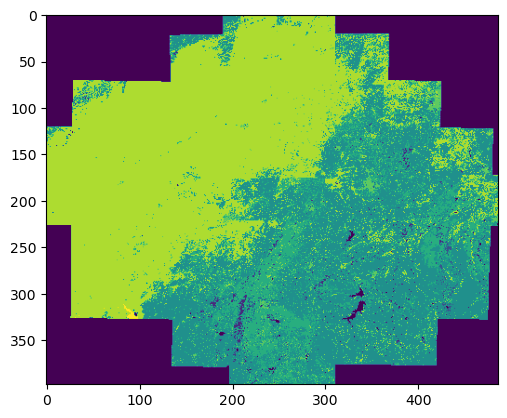

In [114]:
plt.imshow(img.read(1))
